# Classification d’images Fashion-MNIST avec un CNN

## Objectif général

Nous allons construire progressivement un **réseau de neurones convolutif**, ou **CNN** (*Convolutional Neural Network*), capable de reconnaître le type de vêtement représenté sur une image Fashion-MNIST.

Une image sera représentée par une matrice $X$ de taille $28 \times 28$. Chaque nombre de cette matrice indique l’intensité d’un pixel. La réponse attendue est une classe :

$$
y \in \{0,1,\ldots,9\}.
$$

Le travail suivra toujours le même cycle :

1. comprendre et préparer les données ;
2. construire une architecture adaptée ;
3. entraîner le modèle ;
4. évaluer ses performances ;
5. interpréter ses réussites et ses erreurs.

> Dans cette première étape, nous préparons seulement l’environnement. Aucune donnée n’est encore chargée et aucun modèle n’est encore créé.

## Protocole expérimental : éviter la fuite de données

Fashion-MNIST fournit un jeu d’apprentissage officiel et un jeu de test officiel. Plus tard, nous séparerons le jeu d’apprentissage en deux parties disjointes :

$$
D_{\text{apprentissage officiel}} = D_{\text{entraînement}} \cup D_{\text{validation}}.
$$

Le rôle de chaque partie sera différent :

- **entraînement** : calculer et modifier les paramètres du réseau ;
- **validation** : suivre l’apprentissage et choisir les réglages ;
- **test** : mesurer une seule fois la performance finale sur des exemples jamais utilisés pour décider.

Nous imposerons donc notamment :

$$
D_{\text{entraînement}} \cap D_{\text{validation}} = \varnothing
\qquad \text{et} \qquad
D_{\text{test}} \cap D_{\text{entraînement}} = \varnothing
\qquad \text{et} \qquad
D_{\text{test}} \cap D_{\text{validation}} = \varnothing.
$$

Garder le test isolé évite une **fuite de données** : si nous l’utilisions pour choisir le modèle, son score ne représenterait plus honnêtement sa capacité à généraliser.

## 1. Préparer l’environnement et la reproductibilité

L’initialisation des poids, le mélange des images et certaines opérations d’entraînement utilisent des nombres pseudo-aléatoires. Ils sont produits par un algorithme à partir d’une valeur initiale appelée **graine**, ou *seed*.

Nous choisissons ici :

$$
s = 42.
$$

Avec la même graine, le même ordre d’opérations et le même environnement logiciel, nous obtenons généralement les mêmes suites pseudo-aléatoires. Cela facilite la comparaison de deux essais. La graine ne garantit toutefois pas une identité parfaite entre des versions de bibliothèques ou des matériels différents.

`tf.keras.utils.set_random_seed(SEED)` règle ensemble les générateurs de Python, NumPy et TensorFlow. Le mode déterministe demande ensuite à TensorFlow de privilégier des opérations reproductibles ; il peut parfois ralentir les calculs.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

SEED = 42

# Une seule graine pour Python, NumPy et TensorFlow.
tf.keras.utils.set_random_seed(SEED)

# Demande des opérations déterministes lorsque TensorFlow les prend en charge.
tf.config.experimental.enable_op_determinism()

print("TensorFlow :", tf.__version__)
print("NumPy      :", np.__version__)
print("Graine     :", SEED)
print("Environnement prêt.")

TensorFlow : 2.21.0
NumPy      : 2.4.6
Graine     : 42
Environnement prêt.


### Bilan de l’étape

À ce stade :

- les bibliothèques nécessaires au démarrage sont importées ;
- les expériences futures seront plus faciles à reproduire ;
- aucune image n’a encore été chargée ou transformée ;
- le jeu de test n’a pas été consulté.

**Étape suivante :** comprendre comment une image en niveaux de gris devient une matrice de nombres, puis charger Fashion-MNIST.

## 2. Comprendre et charger Fashion-MNIST

### 2.1 Une image en niveaux de gris est une matrice

Une image Fashion-MNIST mesure 28 pixels de hauteur et 28 pixels de largeur. Elle contient donc :

$$
28 \times 28 = 784 \text{ pixels}.
$$

Comme l’image est en niveaux de gris, chaque pixel est représenté par un seul entier. Pour le pixel placé à la ligne $r$ et à la colonne $c$ :

$$
p_{r,c} \in \{0,1,\ldots,255\},
\qquad r,c \in \{0,1,\ldots,27\}.
$$

La valeur 0 représente le noir, 255 le blanc, et les valeurs intermédiaires des nuances de gris. Une image brute $X_i$ est donc une matrice :

$$
X_i \in \{0,\ldots,255\}^{28 \times 28}.
$$

En Python, `images[i, r, c]` désigne le pixel de coordonnées $(r,c)$ dans l’image numéro $i$. Une image est un tableau de rang 2. Un ensemble de $N$ images est un tenseur de rang 3 :

$$
\mathcal{X} \in \{0,\ldots,255\}^{N \times 28 \times 28}.
$$

À chaque image $X_i$ correspond une étiquette entière $y_i$ :

$$
y_i \in \{0,1,\ldots,9\}.
$$

Ces nombres sont seulement des identifiants de catégories : la classe 9 n’est pas « plus grande » que la classe 2.

### 2.2 Charger les données sans les transformer

Keras fournit Fashion-MNIST sous la forme de deux couples :

$$
(X_{\text{train}}, y_{\text{train}})
\qquad \text{et} \qquad
(X_{\text{test}}, y_{\text{test}}).
$$

Nous appelons le premier tableau `images_train_complet_brutes` :

- **train complet** : la partie validation n’a pas encore été extraite ;
- **brutes** : les valeurs sont encore des entiers entre 0 et 255.

Le jeu de test doit être chargé pour être conservé, mais il ne servira ni à choisir l’architecture, ni à régler le modèle, ni à décider quand arrêter l’entraînement. À cette étape, nous ne normalisons rien et nous ne construisons aucun réseau.

In [2]:
(
    (images_train_complet_brutes, etiquettes_train_complet),
    (images_test_brutes, etiquettes_test),
) = tf.keras.datasets.fashion_mnist.load_data()

print("Fashion-MNIST est chargé.")

Fashion-MNIST est chargé.


### 2.3 Vérifier les dimensions et les types

Les dimensions attendues sont :

$$
X_{\text{train}} \in \{0,\ldots,255\}^{60000 \times 28 \times 28},
\qquad
y_{\text{train}} \in \{0,\ldots,9\}^{60000},
$$

$$
X_{\text{test}} \in \{0,\ldots,255\}^{10000 \times 28 \times 28},
\qquad
y_{\text{test}} \in \{0,\ldots,9\}^{10000}.
$$

La première dimension de $X$ doit être égale à la longueur de $y$ : chaque image possède exactement une étiquette.

Les pixels sont stockés avec le type `uint8`, c’est-à-dire un entier non signé sur 8 bits. Huit bits permettent de coder :

$$
2^8 = 256
$$

valeurs différentes, de 0 à 255. Les étiquettes restent des entiers ; nous ne les transformons pas en vecteurs *one-hot*.

In [3]:
print("Images train complètes :", images_train_complet_brutes.shape)
print("Étiquettes train       :", etiquettes_train_complet.shape)
print("Images test            :", images_test_brutes.shape)
print("Étiquettes test        :", etiquettes_test.shape)
print()
print("Type des images       :", images_train_complet_brutes.dtype)
print("Type des étiquettes   :", etiquettes_train_complet.dtype)
print("Pixels du train       :", images_train_complet_brutes.min(), "à", images_train_complet_brutes.max())
print("Classes du train      :", np.unique(etiquettes_train_complet))

assert images_train_complet_brutes.shape == (60_000, 28, 28)
assert etiquettes_train_complet.shape == (60_000,)
assert images_test_brutes.shape == (10_000, 28, 28)
assert etiquettes_test.shape == (10_000,)
assert images_train_complet_brutes.dtype == np.uint8
assert images_test_brutes.dtype == np.uint8
assert np.issubdtype(etiquettes_train_complet.dtype, np.integer)
assert np.issubdtype(etiquettes_test.dtype, np.integer)
assert len(images_train_complet_brutes) == len(etiquettes_train_complet)
assert len(images_test_brutes) == len(etiquettes_test)
assert images_train_complet_brutes.min() == 0
assert images_train_complet_brutes.max() == 255
assert images_test_brutes.min() == 0
assert images_test_brutes.max() == 255
assert np.array_equal(np.unique(etiquettes_train_complet), np.arange(10))
assert np.array_equal(np.unique(etiquettes_test), np.arange(10))

print("\nToutes les vérifications sont réussies.")

Images train complètes : (60000, 28, 28)
Étiquettes train       : (60000,)
Images test            : (10000, 28, 28)
Étiquettes test        : (10000,)

Type des images       : uint8
Type des étiquettes   : uint8
Pixels du train       : 0 à 255
Classes du train      : [0 1 2 3 4 5 6 7 8 9]

Toutes les vérifications sont réussies.


### Bilan de l’étape 2

Nous disposons maintenant de 60 000 images d’apprentissage et de 10 000 images de test. Chaque image brute est une matrice $28 \times 28$ de type `uint8`, et chaque étiquette est un entier compris entre 0 et 9.

Le jeu de test a seulement fait l’objet de contrôles structurels. Il n’a servi à aucune décision. Nous n’avons encore effectué ni normalisation, ni séparation de validation, ni visualisation, ni construction du CNN.

**Étape suivante :** traduire les identifiants 0 à 9 en noms de vêtements et explorer visuellement quelques images du jeu d’apprentissage.

## 3. Associer les classes à des vêtements

### 3.1 Décoder une étiquette

L’étiquette $y_i$ d’une image est un entier entre 0 et 9. Pour la convertir en texte, nous utilisons une table de correspondance $C$ :

$$
\operatorname{nom}(y_i) = C[y_i].
$$

Par exemple, $C[0]$ désigne un T-shirt ou un haut, tandis que $C[9]$ désigne une bottine. Le numéro n’est pas une mesure : il sert uniquement d’adresse dans la table.

| Identifiant | Nom officiel | Traduction française |
|---:|---|---|
| 0 | T-shirt/top | T-shirt / haut |
| 1 | Trouser | Pantalon |
| 2 | Pullover | Pull |
| 3 | Dress | Robe |
| 4 | Coat | Manteau |
| 5 | Sandal | Sandale |
| 6 | Shirt | Chemise |
| 7 | Sneaker | Basket |
| 8 | Bag | Sac |
| 9 | Ankle boot | Bottine |

In [4]:
noms_classes_officiels = np.array(
    [
        "T-shirt/top",
        "Trouser",
        "Pullover",
        "Dress",
        "Coat",
        "Sandal",
        "Shirt",
        "Sneaker",
        "Bag",
        "Ankle boot",
    ]
)

noms_classes_fr = np.array(
    [
        "T-shirt / haut",
        "Pantalon",
        "Pull",
        "Robe",
        "Manteau",
        "Sandale",
        "Chemise",
        "Basket",
        "Sac",
        "Bottine",
    ]
)

assert len(noms_classes_officiels) == 10
assert len(noms_classes_fr) == 10

for identifiant, (nom_officiel, nom_fr) in enumerate(
    zip(noms_classes_officiels, noms_classes_fr)
):
    print(f"{identifiant} : {nom_fr} ({nom_officiel})")

0 : T-shirt / haut (T-shirt/top)
1 : Pantalon (Trouser)
2 : Pull (Pullover)
3 : Robe (Dress)
4 : Manteau (Coat)
5 : Sandale (Sandal)
6 : Chemise (Shirt)
7 : Basket (Sneaker)
8 : Sac (Bag)
9 : Bottine (Ankle boot)


### 3.2 Choisir et afficher une image par classe

Pour chaque classe $k$, nous cherchons uniquement dans le jeu d’apprentissage les indices tels que $y_i=k$. Nous retenons le premier :

$$
i_k = \min \left\{i \in \{0,\ldots,59999\} \mid y_i=k\right\},
\qquad k \in \{0,\ldots,9\}.
$$

L’image affichée pour la classe $k$ sera donc $X_{i_k}$. Cette règle est déterministe : tant que l’ordre du jeu d’apprentissage ne change pas, nous retrouvons les mêmes dix images.

`imshow` convertit visuellement la valeur brute $p$ en une intensité comprise entre 0 et 1 :

$$
g(p)=\frac{p}{255}.
$$

Cette conversion sert seulement à l’affichage : elle ne modifie pas les tableaux. `vmin=0` et `vmax=255` imposent la même échelle de gris aux dix images, et `interpolation="nearest"` laisse visibles les pixels d’origine. Aucune image de test ne sera consultée.

Indices sélectionnés : [1, 16, 5, 3, 19, 8, 18, 6, 23, 0]


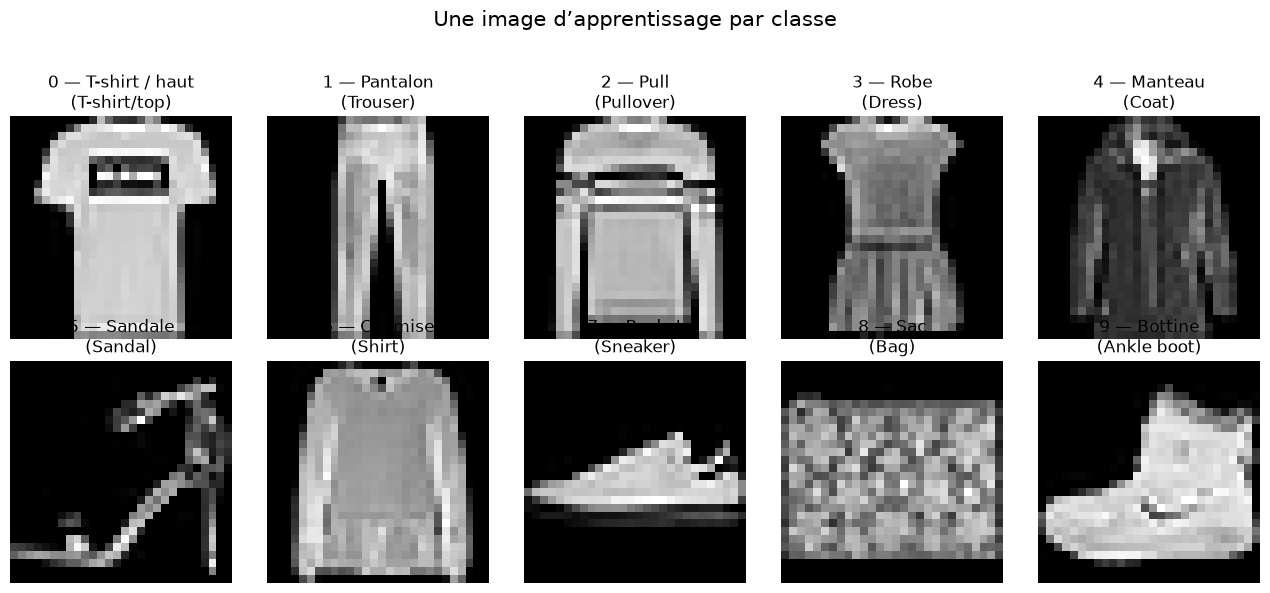

In [5]:
premiers_indices = []

for identifiant in range(10):
    candidats = np.flatnonzero(etiquettes_train_complet == identifiant)
    assert candidats.size > 0
    premiers_indices.append(int(candidats[0]))

assert len(set(premiers_indices)) == 10
assert all(
    etiquettes_train_complet[indice] == identifiant
    for identifiant, indice in enumerate(premiers_indices)
)

print("Indices sélectionnés :", premiers_indices)

figure, axes = plt.subplots(2, 5, figsize=(13, 6))

for identifiant, (axe, indice) in enumerate(
    zip(axes.ravel(), premiers_indices)
):
    axe.imshow(
        images_train_complet_brutes[indice],
        cmap="gray",
        vmin=0,
        vmax=255,
        interpolation="nearest",
    )
    axe.set_title(
        f"{identifiant} — {noms_classes_fr[identifiant]}\n"
        f"({noms_classes_officiels[identifiant]})"
    )
    axe.axis("off")

figure.suptitle("Une image d’apprentissage par classe", fontsize=15)
figure.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

### Lecture prudente et bilan de l’étape 3

Les images paraissent pixelisées parce qu’elles ne contiennent que $28 \times 28$ pixels. Certaines silhouettes sont visuellement très différentes, comme un sac et une bottine. D’autres catégories de hauts peuvent se ressembler. Il s’agit seulement d’observations descriptives, pas encore d’erreurs du modèle : aucun modèle n’a été entraîné.

Une seule image par classe ne représente pas toute la diversité des vêtements. Cette grille ne permet donc aucune conclusion sur l’accuracy, la généralisation ou la difficulté réelle de chaque classe.

Nous avons exclusivement affiché des images d’apprentissage. Les tableaux sont toujours bruts et le jeu de test reste réservé à l’évaluation finale.

**Étape suivante :** étudier la répartition des classes, puis séparer correctement l’apprentissage et la validation.

## 4. Analyser les classes et créer la validation

### 4.1 Mesurer la répartition des classes

Avant de séparer les données, nous vérifions si certaines classes sont plus représentées que d’autres. Pour une classe $k$, son effectif est :

$$
n_k = \sum_{i=0}^{N-1} \mathbf{1}(y_i=k).
$$

La fonction indicatrice $\mathbf{1}(y_i=k)$ vaut 1 si l’image $i$ appartient à la classe $k$, et 0 sinon. Sa proportion est :

$$
p_k = \frac{n_k}{N}.
$$

Ici, $N=60000$. Un jeu est équilibré lorsque les proportions des classes sont proches. Avec dix classes parfaitement équilibrées, nous obtenons :

$$
p_k = \frac{1}{10} = 0.10 = 10\%.
$$

`np.bincount` compte combien de fois chaque étiquette entière apparaît. Nous l’appliquons uniquement aux étiquettes du train officiel.

0 — T-shirt / haut    :  6000 (10.0%)
1 — Pantalon          :  6000 (10.0%)
2 — Pull              :  6000 (10.0%)
3 — Robe              :  6000 (10.0%)
4 — Manteau           :  6000 (10.0%)
5 — Sandale           :  6000 (10.0%)
6 — Chemise           :  6000 (10.0%)
7 — Basket            :  6000 (10.0%)
8 — Sac               :  6000 (10.0%)
9 — Bottine           :  6000 (10.0%)


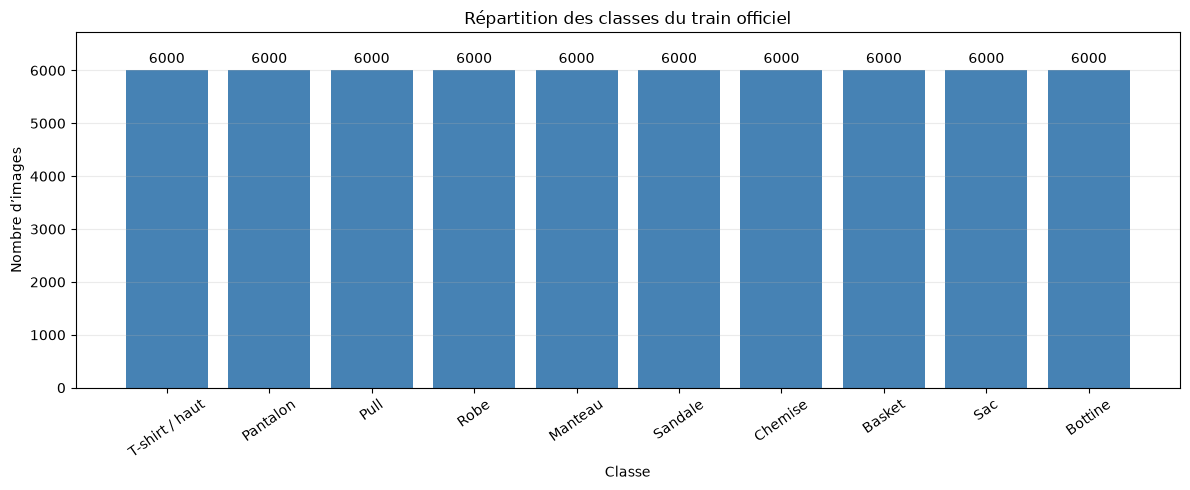

In [6]:
effectifs_train_officiel = np.bincount(
    etiquettes_train_complet,
    minlength=len(noms_classes_fr),
)
proportions_train_officiel = (
    effectifs_train_officiel / len(etiquettes_train_complet)
)

for identifiant in range(len(noms_classes_fr)):
    print(
        f"{identifiant} — {noms_classes_fr[identifiant]:<17} : "
        f"{effectifs_train_officiel[identifiant]:5d} "
        f"({proportions_train_officiel[identifiant]:.1%})"
    )

assert np.array_equal(effectifs_train_officiel, np.full(10, 6_000))

figure, axe = plt.subplots(figsize=(12, 5))
barres = axe.bar(
    noms_classes_fr,
    effectifs_train_officiel,
    color="steelblue",
)
axe.set_title("Répartition des classes du train officiel")
axe.set_xlabel("Classe")
axe.set_ylabel("Nombre d’images")
axe.tick_params(axis="x", rotation=35)
axe.bar_label(barres, padding=3)
axe.set_ylim(0, effectifs_train_officiel.max() * 1.12)
axe.grid(axis="y", alpha=0.25)
figure.tight_layout()
plt.show()

### 4.2 Séparer le train officiel en entraînement et validation

Le futur modèle apprendra ses paramètres sur 80 % des 60 000 images. Les 20 % restantes permettront de suivre sa généralisation pendant le développement :

$$
N_{\text{train}} = 0.80 \times 60000 = 48000,
$$

$$
N_{\text{validation}} = 0.20 \times 60000 = 12000.
$$

Nous séparons d’abord l’ensemble des indices :

$$
I = \{0,1,\ldots,N-1\}.
$$

Cette méthode conserve l’identité des observations et permettra de vérifier formellement qu’aucun indice n’est partagé.

L’option `stratify=etiquettes_train_complet` demande de préserver la proportion de chaque classe. En général :

$$
p_{\text{train},k} \approx p_{\text{validation},k} \approx p_k.
$$

L’option `random_state=SEED` rend le tirage reproductible et `shuffle=True` mélange les indices avant leur répartition. Le test officiel n’intervient jamais dans ce calcul.

In [7]:
from sklearn.model_selection import train_test_split

indices_officiels = np.arange(len(images_train_complet_brutes))

indices_train, indices_validation = train_test_split(
    indices_officiels,
    test_size=0.20,
    random_state=SEED,
    shuffle=True,
    stratify=etiquettes_train_complet,
)

images_train_brutes = images_train_complet_brutes[indices_train]
etiquettes_train = etiquettes_train_complet[indices_train]
images_validation_brutes = images_train_complet_brutes[indices_validation]
etiquettes_validation = etiquettes_train_complet[indices_validation]

print("Images d’entraînement :", images_train_brutes.shape)
print("Images de validation   :", images_validation_brutes.shape)

Images d’entraînement : (48000, 28, 28)
Images de validation   : (12000, 28, 28)


### 4.3 Vérifier la partition et la stratification

Une séparation correcte doit respecter quatre propriétés.

**1. Les tailles attendues**

$$
|I_{\text{train}}|=48000
\qquad \text{et} \qquad
|I_{\text{validation}}|=12000.
$$

**2. La disjonction : aucune image ne doit appartenir aux deux ensembles**

$$
I_{\text{train}} \cap I_{\text{validation}} = \varnothing.
$$

**3. L’exhaustivité : toutes les images du train officiel doivent être conservées**

$$
I_{\text{train}} \cup I_{\text{validation}} = I.
$$

**4. La conservation des proportions**

$$
p_{\text{train},k}=\frac{n_{\text{train},k}}{N_{\text{train}}}
\qquad \text{et} \qquad
p_{\text{validation},k}=\frac{n_{\text{validation},k}}{N_{\text{validation}}}.
$$

Comme les effectifs sont parfaitement divisibles ici, chaque classe doit contenir exactement 4 800 images d’entraînement et 1 200 images de validation, soit 10 % dans les deux cas.

In [8]:
intersection = np.intersect1d(indices_train, indices_validation)
indices_reconstitues = np.sort(
    np.concatenate([indices_train, indices_validation])
)

effectifs_train = np.bincount(etiquettes_train, minlength=10)
effectifs_validation = np.bincount(etiquettes_validation, minlength=10)
proportions_train = effectifs_train / len(etiquettes_train)
proportions_validation = (
    effectifs_validation / len(etiquettes_validation)
)

print(
    f"{'Classe':<18}"
    f"{'Train':>9}"
    f"{'Validation':>12}"
    f"{'% train':>11}"
    f"{'% val.':>10}"
)
for identifiant in range(10):
    print(
        f"{noms_classes_fr[identifiant]:<18}"
        f"{effectifs_train[identifiant]:>9}"
        f"{effectifs_validation[identifiant]:>12}"
        f"{proportions_train[identifiant]:>10.1%}"
        f"{proportions_validation[identifiant]:>10.1%}"
    )

assert images_train_brutes.shape == (48_000, 28, 28)
assert images_validation_brutes.shape == (12_000, 28, 28)
assert etiquettes_train.shape == (48_000,)
assert etiquettes_validation.shape == (12_000,)
assert images_train_brutes.dtype == np.uint8
assert images_validation_brutes.dtype == np.uint8
assert len(np.unique(indices_train)) == len(indices_train)
assert len(np.unique(indices_validation)) == len(indices_validation)
assert intersection.size == 0
assert np.array_equal(indices_reconstitues, indices_officiels)
assert np.array_equal(effectifs_train, np.full(10, 4_800))
assert np.array_equal(effectifs_validation, np.full(10, 1_200))
assert np.allclose(proportions_train, proportions_validation)

print("\nIntersection :", intersection.size, "indice")
print("Union reconstituée :", len(indices_reconstitues), "indices")
print("La partition est disjointe, exhaustive et stratifiée.")

Classe                Train  Validation    % train    % val.
T-shirt / haut         4800        1200     10.0%     10.0%
Pantalon               4800        1200     10.0%     10.0%
Pull                   4800        1200     10.0%     10.0%
Robe                   4800        1200     10.0%     10.0%
Manteau                4800        1200     10.0%     10.0%
Sandale                4800        1200     10.0%     10.0%
Chemise                4800        1200     10.0%     10.0%
Basket                 4800        1200     10.0%     10.0%
Sac                    4800        1200     10.0%     10.0%
Bottine                4800        1200     10.0%     10.0%

Intersection : 0 indice
Union reconstituée : 60000 indices
La partition est disjointe, exhaustive et stratifiée.


### Bilan de l’étape 4

Le train officiel est parfaitement équilibré : chaque classe contient 6 000 images, soit 10 %. Nous l’avons séparé en 48 000 images d’entraînement et 12 000 images de validation.

La partition est reproductible, stratifiée, disjointe et exhaustive. Chaque sous-ensemble conserve 10 % de chaque classe. Le jeu officiel de test est toujours séparé et n’a participé à aucune décision.

Toutes les images sont encore des matrices brutes `uint8` comprises entre 0 et 255. Aucun modèle n’a été construit.

**Étape suivante :** normaliser les pixels et ajouter la dimension de canal attendue par un CNN.

## 5. Préparer les images pour le CNN

### 5.1 Normaliser les intensités des pixels

Les pixels bruts sont des entiers compris entre 0 et 255 :

$$
p \in \{0,1,\ldots,255\}.
$$

Nous les convertissons en nombres décimaux compris entre 0 et 1 avec la transformation :

$$
T(p)=p_{\text{normalisé}}=\frac{\operatorname{float32}(p)}{255}.
$$

Ainsi, $T(0)=0$ et $T(255)=1$. Les distances relatives entre les intensités sont conservées, mais leur échelle numérique devient plus petite, ce qui facilite généralement l’optimisation par descente de gradient.

Le type `float32` est celui couramment utilisé par TensorFlow : il permet les calculs décimaux tout en consommant deux fois moins de mémoire que `float64`. Nous effectuons la conversion avant la division.

La division par 255 est une règle fixe connue à l’avance : elle ne calcule ni moyenne, ni écart-type, ni autre paramètre à partir des données. La même formule peut donc être appliquée au train, à la validation et au test sans fuite de données. Une standardisation fondée sur une moyenne et un écart-type serait différente : ces statistiques devraient être apprises uniquement sur le train.

Nous créons de nouveaux tableaux et conservons les tableaux `*_brutes` intacts. Chaque réexécution repart ainsi des valeurs originales et ne peut pas normaliser deux fois les mêmes pixels.

In [9]:
ECHELLE_PIXEL = np.float32(255.0)

images_train_normalisees = (
    images_train_brutes.astype(np.float32) / ECHELLE_PIXEL
)
images_validation_normalisees = (
    images_validation_brutes.astype(np.float32) / ECHELLE_PIXEL
)
images_test_normalisees = (
    images_test_brutes.astype(np.float32) / ECHELLE_PIXEL
)

ensembles_normalises = [
    ("Entraînement", images_train_brutes, images_train_normalisees),
    ("Validation", images_validation_brutes, images_validation_normalisees),
    ("Test", images_test_brutes, images_test_normalisees),
]

for nom, images_brutes, images_normalisees in ensembles_normalises:
    print(
        f"{nom:<14} : forme={images_normalisees.shape}, "
        f"type={images_normalisees.dtype}, "
        f"plage=[{images_normalisees.min():.1f}, "
        f"{images_normalisees.max():.1f}]"
    )
    assert images_brutes.dtype == np.uint8
    assert images_normalisees.dtype == np.float32
    assert images_normalisees.shape == images_brutes.shape
    assert images_normalisees.min() == 0.0
    assert images_normalisees.max() == 1.0
    assert not np.shares_memory(images_brutes, images_normalisees)

ligne, colonne = 14, 14
pixel_brut = images_train_brutes[0, ligne, colonne]
pixel_normalise = images_train_normalisees[0, ligne, colonne]
assert np.isclose(pixel_normalise, np.float32(pixel_brut) / ECHELLE_PIXEL)
print(
    f"\nExemple — pixel ({ligne}, {colonne}) : "
    f"{pixel_brut} devient {pixel_normalise:.6f}"
)

Entraînement   : forme=(48000, 28, 28), type=float32, plage=[0.0, 1.0]
Validation     : forme=(12000, 28, 28), type=float32, plage=[0.0, 1.0]
Test           : forme=(10000, 28, 28), type=float32, plage=[0.0, 1.0]

Exemple — pixel (14, 14) : 181 devient 0.709804


### 5.2 Ajouter la dimension du canal

Nos lots sont actuellement des tenseurs de rang 3 :

$$
X \in \mathbb{R}^{N \times 28 \times 28}.
$$

Une couche `Conv2D` de Keras utilise par défaut le format `channels_last`, dont l’ordre des axes est :

$$
(N,H,W,C),
$$

où $N$ est le nombre d’images, $H$ la hauteur, $W$ la largeur et $C$ le nombre de canaux. Une image couleur possède généralement trois canaux rouge, vert et bleu. Fashion-MNIST est en niveaux de gris, donc :

$$
C=1.
$$

Nous ajoutons un dernier axe de longueur 1 :

$$
(N,28,28) \longrightarrow (N,28,28,1).
$$

Mathématiquement, le contenu reste identique :

$$
X^{\text{CNN}}_{i,h,w,0}=X^{\text{normalisé}}_{i,h,w}.
$$

L’ajout du canal ne crée donc aucun pixel. Pour une image seule, le futur réseau recevra `input_shape=(28, 28, 1)` ; la dimension variable du lot $N$ n’est pas incluse dans `input_shape`.

In [10]:
assert tf.keras.backend.image_data_format() == "channels_last"

images_train = np.expand_dims(images_train_normalisees, axis=-1)
images_validation = np.expand_dims(
    images_validation_normalisees, axis=-1
)
images_test = np.expand_dims(images_test_normalisees, axis=-1)

FORME_ENTREE_CNN = images_train.shape[1:]

tenseurs_cnn = [
    ("Entraînement", images_train, images_train_normalisees, (48_000, 28, 28, 1)),
    ("Validation", images_validation, images_validation_normalisees, (12_000, 28, 28, 1)),
    ("Test", images_test, images_test_normalisees, (10_000, 28, 28, 1)),
]

for nom, images_cnn, images_normalisees, forme_attendue in tenseurs_cnn:
    print(
        f"{nom:<14} : forme={images_cnn.shape}, "
        f"type={images_cnn.dtype}, "
        f"plage=[{images_cnn.min():.1f}, {images_cnn.max():.1f}]"
    )
    assert images_cnn.shape == forme_attendue
    assert images_cnn.dtype == np.float32
    assert images_cnn.min() == 0.0
    assert images_cnn.max() == 1.0
    assert np.array_equal(images_cnn[..., 0], images_normalisees)

assert FORME_ENTREE_CNN == (28, 28, 1)
print("\nForme d’une entrée du CNN :", FORME_ENTREE_CNN)

Entraînement   : forme=(48000, 28, 28, 1), type=float32, plage=[0.0, 1.0]
Validation     : forme=(12000, 28, 28, 1), type=float32, plage=[0.0, 1.0]
Test           : forme=(10000, 28, 28, 1), type=float32, plage=[0.0, 1.0]



Forme d’une entrée du CNN : (28, 28, 1)


### Bilan de l’étape 5

Pour chaque ensemble, nous avons appliqué la transformation fixe :

$$
p_{\text{normalisé}}=\frac{p_{\text{brut}}}{255}.
$$

Les tenseurs `images_train`, `images_validation` et `images_test` sont désormais de type `float32`, compris entre 0 et 1, et possèdent un canal explicite. Leurs formes sont respectivement `(48000, 28, 28, 1)`, `(12000, 28, 28, 1)` et `(10000, 28, 28, 1)`.

Les données brutes ont été conservées. La transformation du test est strictement identique et n’a appris aucun paramètre ; le test n’a servi à aucune décision. Aucun modèle n’a encore été construit.

**Étape suivante :** comprendre les opérations d’un CNN, puis construire son architecture couche par couche.

## 6. Comprendre et construire le CNN

### 6.1 La convolution 2D

Une image d’entrée est un tenseur $X \in \mathbb{R}^{H \times W \times C_{\text{in}}}$. Une couche convolutive fait glisser plusieurs petits filtres sur cette image. Pour le filtre $f$, Keras calcule en pratique une corrélation croisée :

$$
Z_{i,j,f}=b_f+
\sum_{u=0}^{K_h-1}
\sum_{v=0}^{K_w-1}
\sum_{c=0}^{C_{\text{in}}-1}
W_{u,v,c,f}\,\widetilde{X}_{i+u,j+v,c}.
$$

Dans cette formule, $W_{u,v,c,f}$ est un poids appris, $b_f$ le biais du filtre et $\widetilde{X}$ l’image complétée par du *padding*. Keras appelle cette opération une convolution même si, au sens mathématique strict, le noyau n’est pas retourné.

Le même filtre est utilisé à toutes les positions : c’est le **partage des poids**. Un filtre peut ainsi détecter un motif local, comme un bord, où qu’il apparaisse dans l’image.

Pour un filtre carré de taille $K$, un pas $S$ et un padding $P$, la dimension spatiale de sortie est :

$$
H_{\text{sortie}}=
\left\lfloor\frac{H_{\text{entrée}}+2P-K}{S}\right\rfloor+1.
$$

Avec un noyau $3 \times 3$, `padding="same"` ajoute ici une bordure $P=1$ et le pas vaut $S=1$. La hauteur et la largeur sont donc conservées.

Le nombre de paramètres entraînables d’une convolution est :

$$
(K_h K_w C_{\text{in}}+1)C_{\text{out}},
$$

où le terme $+1$ représente un biais par filtre, et non un biais par pixel.

### 6.2 ReLU et max-pooling

Après chaque convolution, nous appliquons la fonction d’activation ReLU :

$$
\operatorname{ReLU}(z)=\max(0,z).
$$

Elle conserve une réponse positive et remplace une réponse négative par zéro. Sa dérivée, utilisée par la descente de gradient, vaut :

$$
\operatorname{ReLU}'(z)=
\begin{cases}
0 & \text{si } z<0,\\
1 & \text{si } z>0.
\end{cases}
$$

Au point $z=0$, la dérivée mathématique n’est pas définie ; les bibliothèques utilisent une convention numérique. ReLU introduit la non-linéarité qui permet au réseau d’apprendre des relations complexes. Elle ne possède aucun paramètre.

Le max-pooling conserve ensuite la valeur maximale de chaque fenêtre $2 \times 2$. Avec un pas de 2 :

$$
Y_{i,j,c}=\max_{0\leq u<2,\,0\leq v<2}
X_{2i+u,2j+v,c}.
$$

Il divise la hauteur et la largeur par deux :

$$
28 \times 28 \longrightarrow 14 \times 14
\longrightarrow 7 \times 7.
$$

Le pooling réduit le coût de calcul et rend les représentations moins sensibles aux petits déplacements. Il ne possède aucun paramètre entraînable, mais il perd volontairement une partie de la précision spatiale.

### 6.3 Passer des caractéristiques aux probabilités

Après les deux blocs convolutifs, le tenseur a la forme $7 \times 7 \times 64$. `Flatten` le transforme, sans modifier ses valeurs, en un vecteur de longueur :

$$
7 \times 7 \times 64=3136.
$$

Une couche dense calcule :

$$
z=xW+b.
$$

Avec $n_{\text{in}}$ entrées et $n_{\text{out}}$ neurones, elle contient :

$$
(n_{\text{in}}+1)n_{\text{out}}
$$

paramètres, le $+1$ correspondant aux biais.

Le Dropout de taux $r=0.30$ désactive aléatoirement 30 % des activations pendant l’entraînement. Sa probabilité de conservation vaut $q=1-r=0.70$. Le Dropout inversé calcule alors :

$$
\widetilde{h}_j=\frac{m_j}{q}h_j,
\qquad m_j \sim \operatorname{Bernoulli}(q).
$$

Pendant la validation et la prédiction, le Dropout est désactivé. Il aide à limiter le surapprentissage et ne contient aucun paramètre.

La dernière couche dense produit dix **logits** $z_0,\ldots,z_9$. Softmax les transforme en probabilités. Pour éviter des exponentielles inutilement grandes, on peut soustraire $m=\max_j z_j$ sans changer le résultat :

$$
\widehat{p}_k=
\frac{e^{z_k-m}}{\sum_{j=0}^{9}e^{z_j-m}},
\qquad \sum_{k=0}^{9}\widehat{p}_k=1.
$$

La classe prédite sera $\widehat{y}=\operatorname*{argmax}_k \widehat{p}_k$.

### 6.4 Architecture retenue

Le premier bloc apprend 32 motifs simples. Après réduction spatiale, le second bloc combine ces motifs avec 64 filtres. Les activations ReLU sont placées dans des couches séparées afin que chaque opération apparaisse clairement dans le résumé.

| Couche | Forme de sortie, hors lot | Paramètres |
|---|---:|---:|
| Entrée | $28 \times 28 \times 1$ | 0 |
| Conv2D, 32 filtres $3 \times 3$ | $28 \times 28 \times 32$ | 320 |
| ReLU | $28 \times 28 \times 32$ | 0 |
| MaxPool $2 \times 2$ | $14 \times 14 \times 32$ | 0 |
| Conv2D, 64 filtres $3 \times 3$ | $14 \times 14 \times 64$ | 18 496 |
| ReLU | $14 \times 14 \times 64$ | 0 |
| MaxPool $2 \times 2$ | $7 \times 7 \times 64$ | 0 |
| Flatten | 3 136 | 0 |
| Dense | 128 | 401 536 |
| ReLU puis Dropout | 128 | 0 |
| Dense, logits | 10 | 1 290 |
| Softmax | 10 | 0 |

Les calculs des paramètres sont :

$$
(3\times3\times1+1)\times32=320,
$$

$$
(3\times3\times32+1)\times64=18496,
$$

$$
(3136+1)\times128=401536,
$$

$$
(128+1)\times10=1290.
$$

Le total attendu vaut :

$$
320+18496+401536+1290=421642.
$$

La majorité des paramètres se trouve dans la couche dense de 128 neurones, ce qui crée un risque de surapprentissage ; le Dropout aidera à le limiter. À cette étape, le modèle est construit mais pas compilé ni entraîné.

In [11]:
modele_cnn = tf.keras.Sequential(
    [
        tf.keras.layers.Input(shape=FORME_ENTREE_CNN, name="entree"),
        tf.keras.layers.Conv2D(
            filters=32,
            kernel_size=(3, 3),
            strides=(1, 1),
            padding="same",
            activation=None,
            name="conv_1",
        ),
        tf.keras.layers.ReLU(name="relu_1"),
        tf.keras.layers.MaxPooling2D(
            pool_size=(2, 2),
            strides=(2, 2),
            name="pool_1",
        ),
        tf.keras.layers.Conv2D(
            filters=64,
            kernel_size=(3, 3),
            strides=(1, 1),
            padding="same",
            activation=None,
            name="conv_2",
        ),
        tf.keras.layers.ReLU(name="relu_2"),
        tf.keras.layers.MaxPooling2D(
            pool_size=(2, 2),
            strides=(2, 2),
            name="pool_2",
        ),
        tf.keras.layers.Flatten(name="flatten"),
        tf.keras.layers.Dense(
            units=128, activation=None, name="dense_128"
        ),
        tf.keras.layers.ReLU(name="relu_dense"),
        tf.keras.layers.Dropout(rate=0.30, name="dropout"),
        tf.keras.layers.Dense(
            units=10, activation=None, name="logits"
        ),
        tf.keras.layers.Softmax(name="probabilites"),
    ],
    name="cnn_fashion_mnist",
)

modele_cnn.summary()

Model: "cnn_fashion_mnist"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_1 (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_1 (ReLU)                   │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_2 (ReLU)                   │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_dense (ReLU)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ logits (Dense)                  │ (None, 10)             │         1,290 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probabilites (Softmax)          │ (None, 10)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

### 6.5 Vérifier le modèle sans l’entraîner

Dans le résumé Keras, `None` représente la taille variable du lot. Par exemple, `(None, 28, 28, 32)` signifie que chaque image du lot produit 32 cartes de caractéristiques de taille $28 \times 28$.

Nous allons comparer les nombres de paramètres calculés à ceux des couches Keras, puis créer deux images artificielles entièrement nulles :

$$
X_{\text{fictif}} \in \mathbb{R}^{2 \times 28 \times 28 \times 1}.
$$

Le modèle doit produire :

$$
\widehat{P}_{\text{fictif}} \in \mathbb{R}^{2 \times 10},
\qquad \sum_{k=0}^{9}\widehat{p}_{i,k}=1.
$$

`training=False` désactive le Dropout. Ce passage vérifie seulement la compatibilité des dimensions et Softmax ; il ne mesure aucune performance, car les poids viennent juste d’être initialisés. Le lot fictif ne provient ni du train, ni de la validation, ni du test.

In [12]:
parametres_attendus = {
    "conv_1": 320,
    "conv_2": 18_496,
    "dense_128": 401_536,
    "logits": 1_290,
}

for nom_couche, nombre_attendu in parametres_attendus.items():
    nombre_obtenu = modele_cnn.get_layer(nom_couche).count_params()
    print(f"{nom_couche:<10} : {nombre_obtenu:>7} paramètres")
    assert nombre_obtenu == nombre_attendu

NOMBRE_PARAMETRES_CNN = sum(parametres_attendus.values())
assert NOMBRE_PARAMETRES_CNN == 421_642
assert modele_cnn.count_params() == NOMBRE_PARAMETRES_CNN
assert modele_cnn.input_shape == (None, 28, 28, 1)
assert modele_cnn.output_shape == (None, 10)

lot_fictif = tf.zeros((2, *FORME_ENTREE_CNN), dtype=tf.float32)
probabilites_fictives = modele_cnn(lot_fictif, training=False).numpy()
sommes_probabilites = probabilites_fictives.sum(axis=1)

print("\nTotal :", modele_cnn.count_params(), "paramètres")
print("Forme du lot fictif :", lot_fictif.shape)
print("Forme de la sortie  :", probabilites_fictives.shape)
print("Première sortie     :", np.round(probabilites_fictives[0], 4))
print("Sommes des lignes   :", sommes_probabilites)

assert probabilites_fictives.shape == (2, 10)
assert np.all(np.isfinite(probabilites_fictives))
assert np.all((probabilites_fictives >= 0) & (probabilites_fictives <= 1))
np.testing.assert_allclose(sommes_probabilites, np.ones(2), atol=1e-6)

print("\nArchitecture et propagation fictive validées.")

conv_1     :     320 paramètres
conv_2     :   18496 paramètres
dense_128  :  401536 paramètres
logits     :    1290 paramètres



Total : 421642 paramètres
Forme du lot fictif : (2, 28, 28, 1)
Forme de la sortie  : (2, 10)
Première sortie     : [0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1]
Sommes des lignes   : [1. 1.]

Architecture et propagation fictive validées.


### Bilan de l’étape 6

Le CNN contient deux blocs `Conv2D → ReLU → MaxPooling2D` pour extraire progressivement des caractéristiques visuelles, puis un classifieur `Flatten → Dense → ReLU → Dropout → Dense → Softmax`.

Il attend une entrée de forme `(28, 28, 1)`, produit dix probabilités et contient exactement 421 642 paramètres entraînables. Une propagation sur un lot artificiel confirme que chaque ligne de sortie somme à 1.

Le modèle n’a été ni compilé ni entraîné. Aucune image d’entraînement, de validation ou de test n’a été utilisée pour cette vérification structurelle.

**Étape suivante :** comprendre la fonction de perte, l’accuracy et l’optimiseur Adam, puis compiler le CNN.